<a href="https://colab.research.google.com/github/tanay2405/CMPE188_Project_Group13/blob/main/EDA_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 01 EDA: Prediction Task and Fairness Setup
- CMPE 188 Group 13
- Dataset: Pima Indians Diabetes
- ML Engineer - Tanay Allaparti

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 24
DATA_URL = "https://raw.githubusercontent.com/tanay2405/CMPE188_Project_Group13/main/pima_diabetes_train.csv"

df = pd.read_csv(DATA_URL)
print(df.shape)
df.head()

(652, 9)


,pregnancies,glucose,blood_pressure,skin_thickness,insulin,bmi,diabetes_pedigree,age,outcome
0,8,85,55,20,0,24.4,0.136,42,tested_negative
1,2,114,68,22,0,28.7,0.092,25,tested_negative
2,10,101,76,48,180,32.9,0.171,63,tested_negative
3,4,91,70,32,88,33.1,0.446,22,tested_negative
4,0,119,66,27,0,38.8,0.259,22,tested_negative


## 2. Target Variable and Class Balance

The outcome column is contains "tested_positive" or "tested_negative". So we turned it into numbers: 1 for diabetes and 0 for no diabetes. Then we count how many patients are in each group and if one group is much bigger, a model can look accurate just by guessing the bigger group. This allows to learn which metrics to use as well.

In [20]:
df["outcome"] = (df["outcome"] == "tested_positive").astype(int)

print(df["outcome"].value_counts())
print(df["outcome"].value_counts(normalize=True).round(3))

outcome
0    424
1    228
Name: count, dtype: int64
outcome
0    0.65
1    0.35
Name: proportion, dtype: float64


## 3. Handling Missing Data

Some columns like glucose, blood pressure, skin thickness, insulin, and BMI contain zeros. However, this is impossible and the true meaning behind these zeros is that it's not measured. That is why the zeros are repalced with (NaN) values in a copy of the data called df_nan, so they don't mess up the plots.

In [21]:
zero_columns = ["glucose", "blood_pressure", "skin_thickness", "insulin", "bmi"]
features = [c for c in df.columns if c != "outcome"]

df_nan = df.copy()
df_nan[zero_columns] = df_nan[zero_columns].replace(0, np.nan)

## 4. Features vs. Outcome

Each small plot is one feature and it's split into two boxes: patients without diabetes (0) and with diabetes (1). The line in the middle of each box is the typical value. This means that if the two boxes are at different heights, the features will be different between the groups. Having different features is useful for predicting diabetes. If they overlap a lot, it would be less useful.

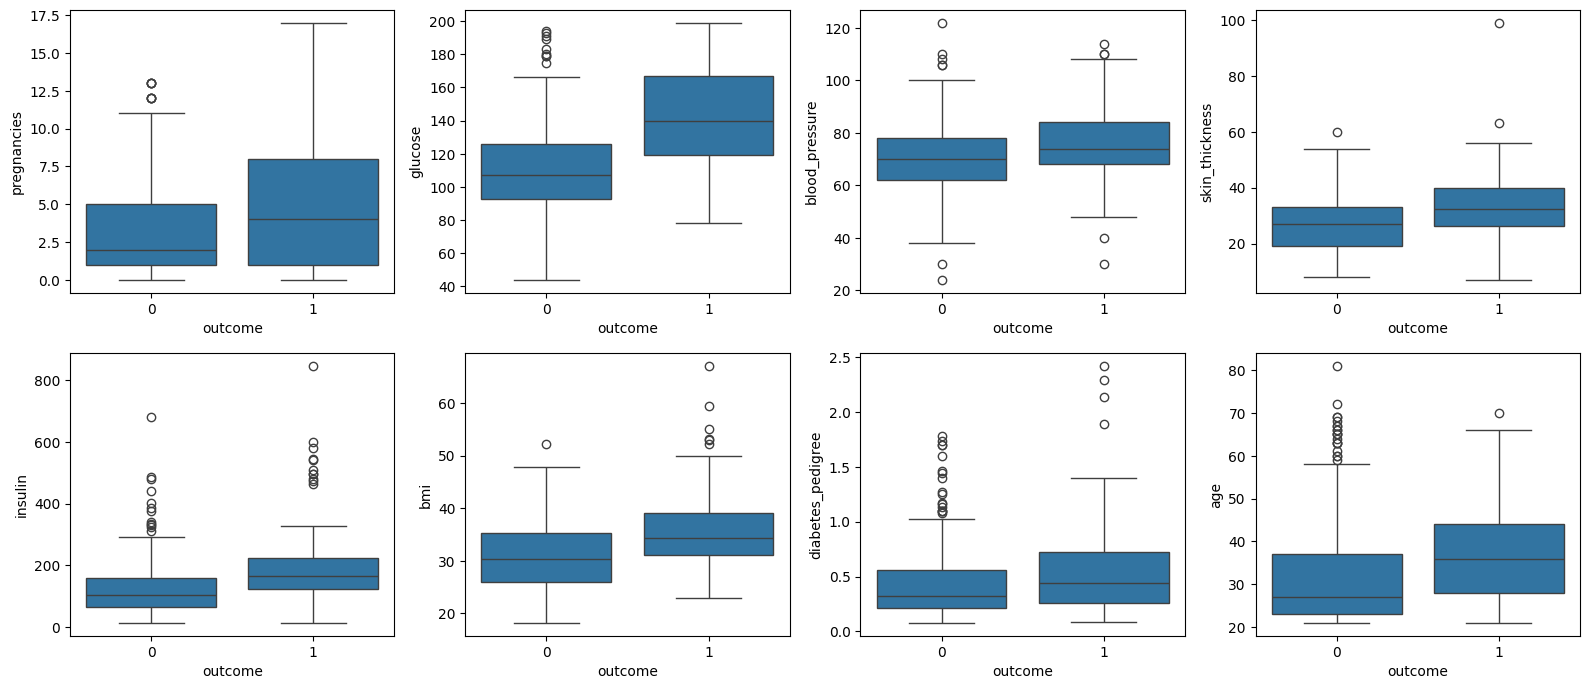

In [22]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.ravel(), features):
    sns.boxplot(data=df_nan, x="outcome", y=col, ax=ax)
plt.tight_layout()
plt.show()

## 5. Correlations

This heatmap shows how strongly each pair of columns moves together. Values close to 1 mean they rise together while values close to 0 mean there is no correlation at all. The outcome row shows which features relate the most to diabetes. Any other features that are strongly related to each other contain information that overlap with each other.

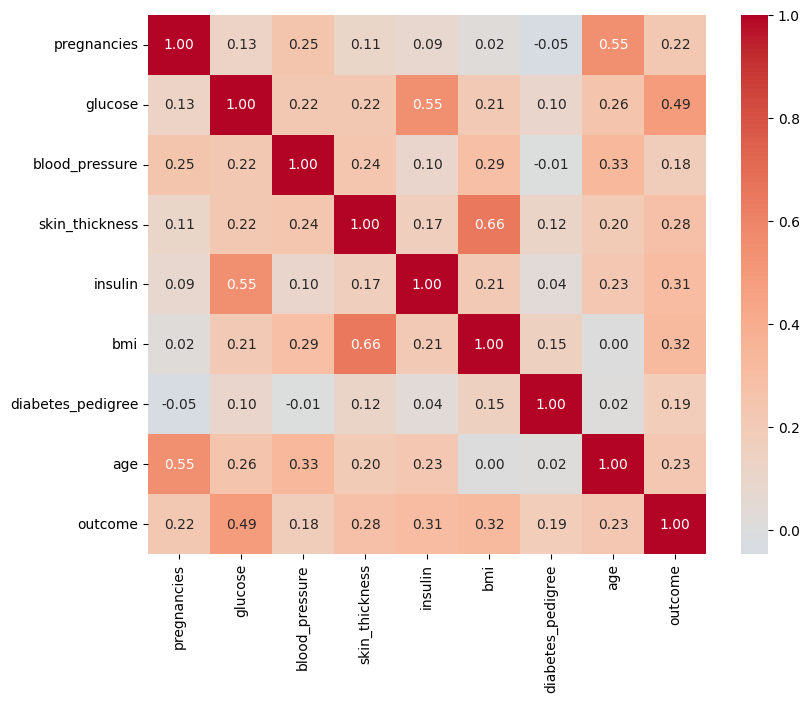

In [23]:
plt.figure(figsize=(9, 7))
sns.heatmap(df_nan.corr(numeric_only=True), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.show()

## 6. Fairness Setup: Age Groups

The dataset doesn't have a gender or race column which is why we use age for the fairness audit. We split the patients into under 30 and 30 or older as that will show how many patients are in each group and how many people in that group has diabetes. If the number of diabetes are very different, we need to keep that in mind when we check if the modle treats both groups fairly.

In [24]:
df["age_group"] = np.where(df["age"] < 30, "under_30", "30_plus")
print(df["age_group"].value_counts())
print(df.groupby("age_group")["outcome"].mean().round(3))

age_group
under_30    339
30_plus     313
Name: count, dtype: int64
age_group
30_plus     0.495
under_30    0.215
Name: outcome, dtype: float64


## 7. Prediction Task Summary
- The data has 652 rows and 9 columns. In this dataset, about 65% of patients do not have diabetes and 35% of patients do have diabetes.
- Glucose is the strongest predicting column of diabetes since many patients with diabetes have a much higher glucose (about 140) than those without diabetets (about 107).
- While BMI, insulin, skin thickness, and age also relate to diabetes, the correlation is a bit weaker compared to glucose.
- There are some overlap between the features. For example, skin thickness and BMI overlap with pregnancies and age.
- The zeros seen in the glucose, blood pressure, skin thickness, insulin, and BMI columns are considered as missing values.
- In terms of age, diabetes is much more common in the 30+ age group (about 49%) than in the under 30 group (about 22%). This is an important metric to remember when checking fairness later.